# 03 · Does SAG hold up outside the QC set? A test on 2,290 MapBiomas reference points

**Author:** Meera Mehta, MIT Analytics Lab × Cropin, Nov 2026
**Inputs:**
- `data/gee_exports/ref_sag_timeseries_{PR,SC,RS}.csv` (from `gee/04_sag_mapbiomas_ref_export.js`);
- `data/processed/mapbiomas_ref_south.csv` (from `src/build_mapbiomas_ref_south.py`);
- `data/gee_exports/qc_sag_timeseries.csv` plus the notebook-01 inputs, for the comparison with the QC set.

**Outputs:** `figures/03*.png`

**Why this notebook.** Notebook 02 found that SAG (how dark-green the canopy looks in Oct–Jan)
separates plantations from forest well, with AUC 0.87. But it was tested only on Cropin's 433 QC polygons,
a small sample chosen by Cropin in a way we don't know. Here we test the **same SAG measure** on a
completely separate labelled set: MapBiomas' own hand-interpreted validation points in PR, SC and RS
whose class (3 = forest, 9 = plantation) was the same in 2016, 2020 and 2022.

**What this test can and cannot say.**
- **It can say** whether SAG separates plantation from forest in general in southern Brazil, not
  just on the QC cases.
- **It cannot say** how many of *Cropin's alerts* we would remove. These points are a landscape
  sample, not alerts, and keeping only stable-class points removes the hardest cases. That question needs
  a random sample of alerts (see the end).

Statistics follow notebooks 01 and 02, using the helpers in `src/qc_analysis.py`.

In [1]:
import sys, warnings, glob
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import beta
from qc_analysis import *

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)
set_style()
SEED, N_BOOT = 0, 2000
np.random.seed(SEED)
pd.set_option("display.precision", 3, "display.width", 140)

REF_FILES = sorted(glob.glob(str(DATA / "gee_exports/ref_sag_timeseries_*.csv")))
assert len(REF_FILES) == 3, f"expected 3 ref_sag_timeseries files (PR, SC, RS), found {len(REF_FILES)}: run gee/04"

def season_of(dates):
    # Cropin's SAG season: Oct 1 to Jan 30, named by the October year (same as notebook 02).
    m, yr = dates.dt.month, dates.dt.year
    in_win = (m >= 10) | ((m == 1) & (dates.dt.day <= 30))
    return np.where(in_win, np.where(m >= 10, yr, yr - 1), -1)

def sag_features(sag, index):
    # One value per point/polygon. Copies from overlapping tiles are averaged per date first.
    day = sag.groupby(["id", "date"], as_index=False).agg(sag=("sag", "mean"))
    day["month"], day["season"] = day["date"].dt.month, season_of(day["date"])
    win = day[day.season.isin(range(2019, 2026))]
    f = pd.DataFrame(index=index)
    f["sag_octjan"] = win.groupby("id").sag.mean()
    f["sag_octjan_to2022"] = win[win.season.isin(range(2019, 2023))].groupby("id").sag.mean()
    f["sag_junaug"] = day[day.month.isin([6, 7, 8]) & (day.date.dt.year <= 2025)].groupby("id").sag.mean()
    f["n_dates_octjan"] = win.groupby("id").size()
    return f, day

def share_ci(k, n):
    # Clopper-Pearson exact 95% CI for a share k/n, in %.
    lo = beta.ppf(0.025, k, n - k + 1) if k > 0 else 0.0
    hi = beta.ppf(0.975, k + 1, n - k) if k < n else 1.0
    return 100 * k / n, 100 * lo, 100 * hi

## (i) Data
Each reference point is widened to a 15 m circle (about 3×3 Sentinel-2 pixels), close to the size of a
QC polygon. The SAG settings are identical to `gee/03`: same formula, same dark-pixel rule, same cloud mask.

In [2]:
ref_ts = pd.concat([pd.read_csv(f, parse_dates=["date"]) for f in REF_FILES]).rename(columns={"mean": "sag", "count": "npix"})
ref = pd.read_csv(DATA / "processed/mapbiomas_ref_south.csv").set_index("id")
assert set(ref_ts.id) == set(ref.index), "points missing from the export"
f_ref, day_ref = sag_features(ref_ts, ref.index)
ref = ref.join(f_ref)
ref["y"] = (ref.label == "plantation").astype(int)
print(f"reference SAG rows: {len(ref_ts):,} | points: {ref_ts.id.nunique():,} | dates {ref_ts.date.min().date()} to {ref_ts.date.max().date()}")
print("points per class:", ref.label.value_counts().to_dict(), "| high-confidence:", int(ref.high_conf.sum()))
print("valid Oct–Jan dates per point (median, min):", int(ref.n_dates_octjan.median()), int(ref.n_dates_octjan.min()))
print("points with no valid date in each window:", ref[["sag_octjan", "sag_octjan_to2022", "sag_junaug"]].isna().sum().to_dict())

# QC set, built exactly as in notebook 02
qc = add_features(load_qc()).set_index("id")
qc_ts = pd.read_csv(DATA / "gee_exports/qc_sag_timeseries.csv", parse_dates=["date"]).rename(columns={"mean": "sag", "count": "npix"})
f_qc, day_qc = sag_features(qc_ts, qc.index)
qc = qc[["y", "qc_label"]].join(f_qc)
print(f"QC polygons: {len(qc)} ({int(qc.y.sum())} plantation, {int((qc.y == 0).sum())} forest)")

reference SAG rows: 620,368 | points: 2,290 | dates 2019-01-01 to 2026-01-31
points per class: {'forest': 1762, 'plantation': 528} | high-confidence: 1448
valid Oct–Jan dates per point (median, min): 52 1
points with no valid date in each window: {'sag_octjan': 3, 'sag_octjan_to2022': 11, 'sag_junaug': 0}
QC polygons: 433 (310 plantation, 123 forest)


## (ii) Does SAG separate plantation from forest on the reference points?
**AUC** is the chance that a random plantation has a higher SAG than a random forest (0.5 = coin flip,
1 = perfect). The 95% CI comes from 2,000 bootstrap resamples of the points. The **p-value** (Mann–Whitney U,
Holm-corrected across this table) is the chance of a gap this large if the two classes really had the same
SAG distribution. "High-confidence" means all 3 MapBiomas interpreters agreed and the point is not on a class edge.

In [3]:
def auc_row(df, col, name):
    ok = df[col].notna()
    yy, xx = df.loc[ok, "y"].values, df.loc[ok, col].values
    a, lo, hi = auc_ci(yy, xx, N_BOOT, SEED)
    return dict(test=name, n_plantation=int(yy.sum()), n_forest=int((yy == 0).sum()),
                median_plantation=np.median(xx[yy == 1]), median_forest=np.median(xx[yy == 0]),
                AUC=a, ci_low=lo, ci_high=hi, direction=auc_oriented(yy, xx)[1],
                p_raw=mwu_test(xx[yy == 1], xx[yy == 0]))

rows = [auc_row(ref, "sag_octjan", "Reference: SAG Oct–Jan, 7 seasons"),
        auc_row(ref, "sag_octjan_to2022", "Reference: SAG Oct–Jan, seasons 2019/20–2022/23 only"),
        auc_row(ref, "sag_junaug", "Reference: SAG Jun–Aug (winter)"),
        auc_row(ref[ref.high_conf == 1], "sag_octjan", "Reference, high-confidence points"),
        auc_row(ref[ref.high_conf == 0], "sag_octjan", "Reference, other points"),
        auc_row(ref[ref.edge2020 == 1], "sag_octjan", "Reference, points on a class edge")]
rows += [auc_row(ref[ref.state == s], "sag_octjan", f"Reference, {s} only") for s in ["PR", "SC", "RS"]]
rows += [auc_row(qc, "sag_octjan", "QC polygons (notebook 02), for comparison")]
T = pd.DataFrame(rows)
T["p_holm"] = holm(T.p_raw)
display(T.drop(columns="p_raw").round(3))

,test,n_plantation,n_forest,median_plantation,median_forest,AUC,ci_low,ci_high,direction,p_holm
0,"Reference: SAG Oct–Jan, 7 seasons",526,1761,159.386,151.721,0.895,0.879,0.910,higher in plantations,0.0
1,"Reference: SAG Oct–Jan, seasons 2019/20–2022/2...",520,1759,159.879,151.875,0.892,0.876,0.908,higher in plantations,0.0
2,Reference: SAG Jun–Aug (winter),528,1762,165.623,163.164,0.694,0.667,0.719,higher in plantations,0.0
3,"Reference, high-confidence points",282,1165,160.013,151.502,0.930,0.913,0.948,higher in plantations,0.0
4,"Reference, other points",244,596,158.761,152.133,0.836,0.807,0.864,higher in plantations,0.0
5,"Reference, points on a class edge",106,372,158.607,152.045,0.847,0.810,0.882,higher in plantations,0.0
6,"Reference, PR only",174,612,159.139,151.956,0.875,0.843,0.905,higher in plantations,0.0
7,"Reference, SC only",194,555,158.626,152.596,0.862,0.833,0.889,higher in plantations,0.0
8,"Reference, RS only",158,594,160.472,150.877,0.939,0.917,0.959,higher in plantations,0.0
9,"QC polygons (notebook 02), for comparison",310,123,160.326,151.880,0.870,0.830,0.907,higher in plantations,0.0


**Reading the table.**
- **The ranking replicates.** On 2,287 independent points, SAG Oct–Jan has an AUC of about 0.89, slightly
  *higher* than on the QC set (0.87). The plantation and forest medians (about 159–160° vs 152°) are almost
  the same in both datasets.
- **Not an artefact of later harvests.** The labels stop in 2022, so we repeated the test with the seasons up to 2022/23 only:
  practically no change.
- **Cleaner labels give a better result.** On points where all interpreters agreed and that aren't on an edge, the AUC is
  about 0.93; on the rest, about 0.84. Part of SAG's apparent error is label noise.
- **Winter is weaker**, as in notebook 02.
- It works in all three states. It is strongest in RS and weakest in SC.

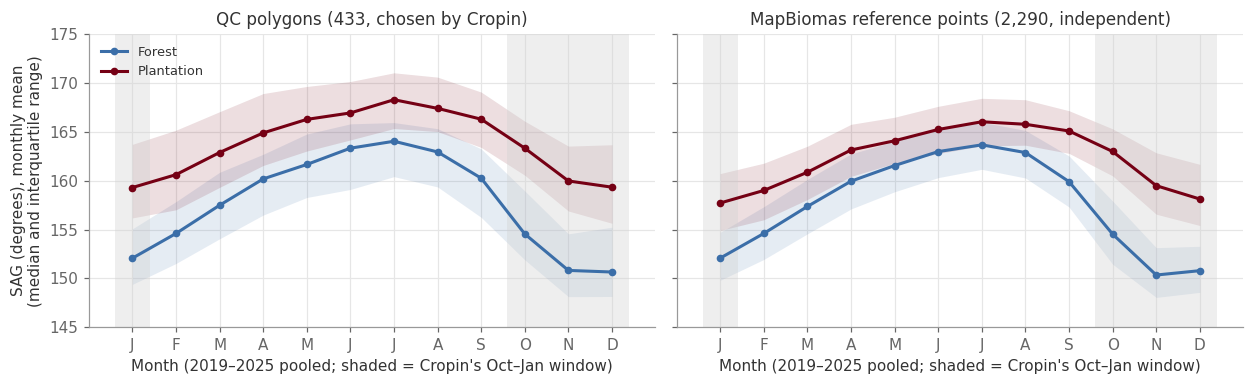

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.6), sharey=True)
mon_ref = day_ref[day_ref.date < "2026-01-01"].groupby(["id", "month"]).sag.mean().unstack()
mon_qc = day_qc[day_qc.date < "2026-01-01"].groupby(["id", "month"]).sag.mean().unstack()
for ax, mon, lab_of, title in [(axs[0], mon_qc, qc.qc_label, "QC polygons (433, chosen by Cropin)"),
                               (axs[1], mon_ref, ref.label, "MapBiomas reference points (2,290, independent)")]:
    for lab in ["forest", "plantation"]:
        sub = mon.loc[lab_of.index[lab_of == lab]]
        ax.plot(range(1, 13), sub.median().values, color=PAL[lab], marker="o", ms=4, label=LABELS[lab].split(" (")[0])
        ax.fill_between(range(1, 13), sub.quantile(.25).values, sub.quantile(.75).values, color=PAL[lab], alpha=0.13, lw=0)
    for a, b in [(9.6, 12.4), (0.6, 1.4)]:
        ax.axvspan(a, b, color=PAL["light"], alpha=0.35, lw=0)
    ax.set_xticks(range(1, 13), list("JFMAMJJASOND"))
    ax.set_xlabel("Month (2019–2025 pooled; shaded = Cropin's Oct–Jan window)"); ax.set_title(title)
axs[0].set_ylabel("SAG (degrees), monthly mean\n(median and interquartile range)"); axs[0].set_ylim(145, 175)
axs[0].legend(loc="upper left", fontsize=8.5)
plt.tight_layout(); savefig(fig, "03i_sag_by_month_qc_vs_ref"); plt.show()

## (iii) Does a cutoff carry over between datasets?
The practical rule is "flag as plantation if SAG ≥ cutoff", with the cutoff chosen so that at most **5% of
forest** is flagged (hidden). With a single feature there is nothing to fit except the cutoff. So we choose it on one
dataset and apply it unchanged to the other. Shares come with exact (Clopper–Pearson) 95% CIs.

In [5]:
def cut5(df):
    return threshold_hiding_at_most(df.loc[df.y == 0, "sag_octjan"].dropna().values, 0.05)

rows = []
for src_name, src in [("reference", ref), ("QC", qc)]:
    t = cut5(src)
    for dst_name, dst in [("reference", ref), ("QC", qc)]:
        s, yy = dst.sag_octjan, dst.y
        ok = s.notna()
        kp, np_ = int(((s >= t) & (yy == 1) & ok).sum()), int(((yy == 1) & ok).sum())
        kf, nf = int(((s >= t) & (yy == 0) & ok).sum()), int(((yy == 0) & ok).sum())
        cp, cf = share_ci(kp, np_), share_ci(kf, nf)
        rows.append({"cutoff chosen on": src_name, "cutoff (degrees)": round(t, 2), "applied to": dst_name,
                     "plantations flagged %": f"{cp[0]:.1f} ({cp[1]:.1f}–{cp[2]:.1f})",
                     "forests hidden %": f"{cf[0]:.1f} ({cf[1]:.1f}–{cf[2]:.1f})", "forests hidden n": f"{kf}/{nf}",
                     "same data (in-sample)": src_name == dst_name})
X = pd.DataFrame(rows)
display(X)

print("Forest SAG Oct–Jan, upper tail (degrees):")
display(pd.DataFrame({n: df.loc[df.y == 0, "sag_octjan"].quantile([.5, .75, .9, .95]).round(2)
                      for n, df in [("reference forest", ref), ("QC forest", qc)]}).T)

,cutoff chosen on,cutoff (degrees),applied to,plantations flagged %,forests hidden %,forests hidden n,same data (in-sample)
0,reference,159.44,reference,49.4 (45.1–53.8),5.0 (4.0–6.1),88/1761,True
1,reference,159.44,QC,56.8 (51.1–62.4),13.8 (8.3–21.2),17/123,False
2,QC,160.96,reference,35.4 (31.3–39.6),2.8 (2.1–3.7),49/1761,False
3,QC,160.96,QC,44.2 (38.6–49.9),4.9 (1.8–10.3),6/123,True


Forest SAG Oct–Jan, upper tail (degrees):


,0.50,0.75,0.90,0.95
reference forest,151.72,154.23,157.20,159.44
QC forest,151.88,155.48,160.22,160.96


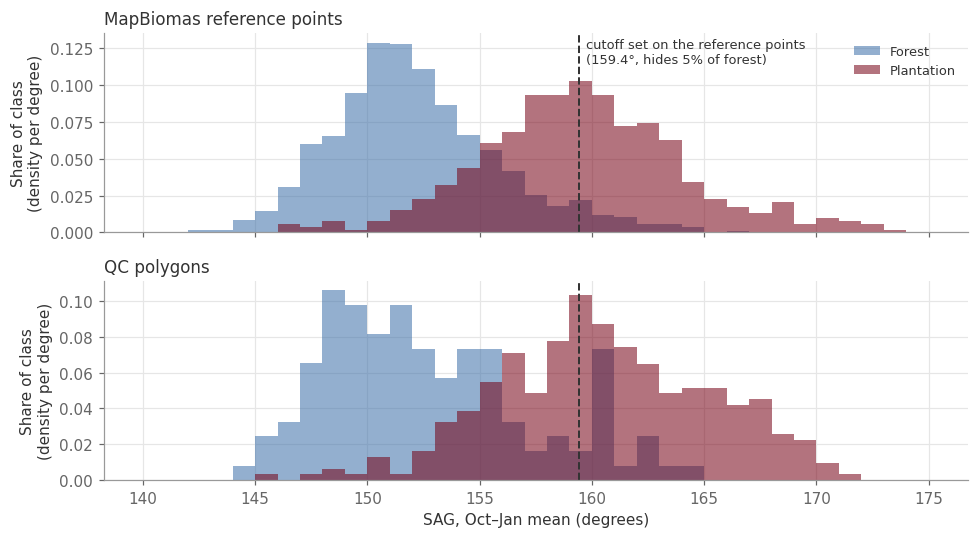

In [6]:
fig, axs = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
bins = np.arange(140, 176, 1)
t_ref = cut5(ref)
for ax, df, title in [(axs[0], ref, "MapBiomas reference points"), (axs[1], qc, "QC polygons")]:
    for lab, yv in [("forest", 0), ("plantation", 1)]:
        ax.hist(df.loc[df.y == yv, "sag_octjan"].dropna(), bins=bins, density=True, alpha=0.55,
                color=PAL[lab], label=LABELS[lab].split(" (")[0])
    ax.axvline(t_ref, color=PAL["ink"], ls="--", lw=1.3)
    ax.set_ylabel("Share of class\n(density per degree)"); ax.set_title(title, loc="left")
axs[0].text(t_ref + 0.3, axs[0].get_ylim()[1] * 0.85, f"cutoff set on the reference points\n({t_ref:.1f}°, hides 5% of forest)", fontsize=8.5)
axs[0].legend(loc="upper right", fontsize=8.5)
axs[1].set_xlabel("SAG, Oct–Jan mean (degrees)")
plt.tight_layout(); savefig(fig, "03ii_cutoff_transfer"); plt.show()

**Reading the cutoff table.**
- **The ranking transfers; the cutoff doesn't.** A cutoff that hides 5% of reference forest hides about **14% of QC
  forest** (17 of 123). Applied the other way, the QC cutoff is very cautious on the reference points: it hides about 3% of forest
  but flags only about a third of plantations.
- **Why.** The typical forest looks the same in both sets (median about 152°), but **QC forests have a
  heavier upper tail**: more of them look as dark-green as plantations. That matches the "dark native pine" cases
  from notebook 02. Cropin's alerts likely over-represent the hard, plantation-looking forests, exactly the ones
  a cleared-forest alert would pick up.
- **Implication.** SAG is a genuinely useful signal, not a quirk of the QC set. But a **cutoff must be set on
  alerts**, not on the general landscape, or it will hide more real deforestation than intended.

## Caveats
- **Not an alert sample.** The reference points are a landscape sample filtered to stable classes, so they don't measure the
  share of false alarms removed in production.
- **Label sources differ.** MapBiomas interpreters labelled 30 m Landsat pixels; Cropin labelled polygons. Some
  of the gap in the upper tail could come from labelling differences, not real differences between the sets.
- **QC forests are few.** "14% hidden" rests on 17 of 123 forests; see the CI.

## Next steps
1. **A random sample of alerts**, labelled blind (from Cropin, or rebuilt in GEE), to set and check the cutoff where it is used.
2. Look at the QC forests above the reference cutoff on high-resolution imagery: native *Araucaria*, or mislabelled?
3. Compare with Julia's `sag_oct_nov_mean` on her points (note: her window is Oct–Nov, ours Oct–Jan).